# Study 9: does the GP coherence field actually do any work?

**The question this notebook answers.** The fitted coherence field looks nearly flat, yet the model
predicts prevalence well (r~0.94). This notebook shows *why*: the **per-feature linking function
absorbs almost all the feature-level variance**, leaving the GP coherence field nearly irrelevant
for prediction. It then tests the fix (linking shapes SHARED across features) and shows the GP
*does* matter — preferring a local length scale and beating the flat null — once the linking
function can't cheat.

This is a **read-only diagnostic** (does not modify committed posteriors). It relies on the
`shared_shapes` option added to `inference.py` (`fit_link_shapes_shared` + flag).

**Roadmap:**
1. Setup + the two linking modes explained.
2. Variance decomposition: where does the per-feature prediction variance come from?
3. The killer test: replace the coherence field with a CONSTANT — do predictions change?
4. Was this in the OLD code too? (yes — even the dramatic beta=16 field barely drove predictions)
5. Shared-shapes: the GP field comes alive. Controlled ls profile (VBMC is unstable here).
6. Full-vs-null under shared shapes: does distance-based generalization matter?


In [1]:
import os
os.environ.setdefault("JAX_ENABLE_X64", "1")
import sys; sys.path.insert(0, ".")
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import inference as inf

geom = inf.load_geometry()
J = geom['J']
responses_cond, _ = inf.load_responses('../../data/study9_prereg.csv')
emp_cond = {c: np.array(responses_cond[c]).mean(0) for c in inf.CONDITIONS}

# the fitted (new, seeded) study-9 params
FULL = dict(ls=0.978, mu=0.006, sig=0.526, beta=0.907)
print("study-9 fitted params (new seeded):", FULL)
print("conditions:", inf.CONDITIONS)


study-9 fitted params (new seeded): {'ls': 0.978, 'mu': 0.006, 'sig': 0.526, 'beta': 0.907}
conditions: ['physical', 'diet', 'personality', 'heterogeneous']


## The two linking modes

The generative model (model_jax.py) is a mixture per feature j:

    p'_j  ~  P(z=1)_j · Beta(a_kl, b_kl)  +  (1 - P(z=1)_j) · Beta(a_nkl, b_nkl)

`P(z=1)` is the GP **coherence field** — this is what the length-scale / distance story is about.
The `Beta` components are the **linking function** (how latent coherence maps to slider ratings).

- **per-feature** (current default, `fit_link_shapes`): a separate Beta-pair PER feature (J×4 params).
  Each feature can encode its own mean directly -> the coherence weight becomes redundant.
- **shared** (`fit_link_shapes_shared`): ONE Beta-pair for ALL features (4 params). Only the
  coherence field P(z=1) can distinguish features -> forces the GP to do the work.


## 1. Variance decomposition: where does the per-feature prediction variance come from?

In [2]:
ls, mu, sig, beta = FULL['ls'], FULL['mu'], FULL['sig'], FULL['beta']
_, shapes, _ = inf.total_log_lik_free_shapes(geom, responses_cond, ls, mu, sig, beta_speaker=beta, return_shapes=True)
mean_kl  = shapes[:,0]/(shapes[:,0]+shapes[:,1])
mean_nkl = shapes[:,2]/(shapes[:,2]+shapes[:,3])
pz1 = inf.prior_pz1_modes(geom, ls, mu, sig, beta_speaker=beta)

rows=[]
for c in inf.CONDITIONS:
    p=np.asarray(pz1[c]); pred=p*mean_kl+(1-p)*mean_nkl
    rows.append({'condition':c, 'emp_std':round(emp_cond[c].std(),3),
                 'pred_std':round(pred.std(),3),
                 'coherence(pz1)_std':round(float(p.std()),4),
                 'pred_range':f"[{pred.min():.2f},{pred.max():.2f}]"})
print(pd.DataFrame(rows).to_string(index=False))
print(f"\nlinking-shape per-feature means: mean_kl std={mean_kl.std():.3f}, mean_nkl std={mean_nkl.std():.3f}")
print("--> the coherence field (pz1) std ~0.004 is ~20x SMALLER than the prediction std (~0.08).")
print("    The per-feature LINKING SHAPES (std 0.05-0.12) carry the feature variance, not coherence.")


    condition  emp_std  pred_std  coherence(pz1)_std  pred_range
     physical    0.077     0.080              0.0040 [0.45,0.72]
         diet    0.098     0.081              0.0039 [0.45,0.72]
  personality    0.118     0.081              0.0040 [0.45,0.72]
heterogeneous    0.084     0.081              0.0015 [0.45,0.72]

linking-shape per-feature means: mean_kl std=0.054, mean_nkl std=0.123
--> the coherence field (pz1) std ~0.004 is ~20x SMALLER than the prediction std (~0.08).
    The per-feature LINKING SHAPES (std 0.05-0.12) carry the feature variance, not coherence.


## 2. The killer test: replace the coherence field with a CONSTANT

If predictions barely change when we flatten the field entirely, the field isn't doing the work.

In [3]:
rows=[]
for c in inf.CONDITIONS:
    p=np.asarray(pz1[c]); pred=p*mean_kl+(1-p)*mean_nkl
    pconst=np.full_like(p,p.mean()); pred_c=pconst*mean_kl+(1-pconst)*mean_nkl
    rows.append({'condition':c,
                 'r(full field)':round(np.corrcoef(pred,emp_cond[c])[0,1],3),
                 'r(CONSTANT field)':round(np.corrcoef(pred_c,emp_cond[c])[0,1],3),
                 'r(coherence alone)':round(np.corrcoef(p,emp_cond[c])[0,1],3)})
df=pd.DataFrame(rows)
print(df.to_string(index=False))
print(f"\nmean r: full={df['r(full field)'].mean():.3f}  constant-field={df['r(CONSTANT field)'].mean():.3f}")
print("--> replacing the field with a constant BARELY changes predictions. The GP field is nearly inert.")


    condition  r(full field)  r(CONSTANT field)  r(coherence alone)
     physical          0.892              0.889               0.062
         diet          0.925              0.923               0.368
  personality          0.968              0.966               0.655
heterogeneous          0.968              0.968               0.339

mean r: full=0.938  constant-field=0.936
--> replacing the field with a constant BARELY changes predictions. The GP field is nearly inert.


## 3. Was this in the OLD code too?

The old committed fit had beta=16 and a visually DRAMATIC field. But did that field actually drive
predictions, or did the per-feature linking still do the work? (The per-feature linking code is
character-for-character identical old vs new — verified.)

In [4]:
rows=[]
for tag,(L,M,S,B) in [('OLD committed (beta=16, dramatic-looking)', (0.205,-0.397,0.782,16.035)),
                      ('NEW (beta=0.9, flat-looking)',              (0.978,0.006,0.526,0.907))]:
    _, sh, _ = inf.total_log_lik_free_shapes(geom, responses_cond, L,M,S, beta_speaker=B, return_shapes=True)
    mkl=sh[:,0]/(sh[:,0]+sh[:,1]); mnkl=sh[:,2]/(sh[:,2]+sh[:,3])
    pz=inf.prior_pz1_modes(geom,L,M,S,beta_speaker=B)
    rf,rc=[],[]
    for c in inf.CONDITIONS:
        p=np.asarray(pz[c]); rf.append(np.corrcoef((p*mkl+(1-p)*mnkl),emp_cond[c])[0,1])
        pc=np.full_like(p,p.mean()); rc.append(np.corrcoef((pc*mkl+(1-pc)*mnkl),emp_cond[c])[0,1])
    fieldstd=np.mean([np.asarray(pz[c]).std() for c in inf.CONDITIONS])
    rows.append({'fit':tag,'field_std':round(fieldstd,3),
                 'r(full)':round(np.mean(rf),3),'r(const field)':round(np.mean(rc),3),
                 'field contributes':round(np.mean(rf)-np.mean(rc),3)})
print(pd.DataFrame(rows).to_string(index=False))
print("\n--> even the OLD dramatic field (std 0.13) contributed only ~+0.01 to r. Same issue, masked by")
print("    high beta making the field LOOK impactful. Not a refactor regression -- pre-existing.")


                                      fit  field_std  r(full)  r(const field)  field contributes
OLD committed (beta=16, dramatic-looking)      0.108    0.917           0.904              0.012
             NEW (beta=0.9, flat-looking)      0.003    0.938           0.937              0.002

--> even the OLD dramatic field (std 0.13) contributed only ~+0.01 to r. Same issue, masked by
    high beta making the field LOOK impactful. Not a refactor regression -- pre-existing.


## 4. Shared-shapes: does the GP field come alive?

Now force the linking function to be SHARED across features, so only coherence can distinguish them.
NOTE: VBMC is numerically unstable under shared shapes (runs away to extreme beta/ls). So we use a
**controlled ls profile** at fixed (mu=0, sigma=0.5, beta=3) instead -- the trustworthy method.

SHARED shapes, controlled (mu=0, sigma=0.5, beta=3):
   ls  logZ  mean_r  pz1_std
 0.01 516.3  -0.148   0.0031
 0.05 525.5   0.201   0.0178
 0.10 531.0   0.286   0.0305
 0.20 549.1   0.329   0.0361
 0.40 564.0   0.342   0.0238
 0.80 562.5   0.354   0.0083
 1.50 554.4   0.357   0.0026
 3.00 546.9   0.359   0.0007
10.00 543.3   0.359   0.0001

--> shared-shapes logZ PEAKS at ls=0.4 (local!) with an ACTIVE field (pz1_std>0).
    Flat null (ls=10) logZ=543.3 vs peak 564.0: GP beats flat by +20.7 logZ.


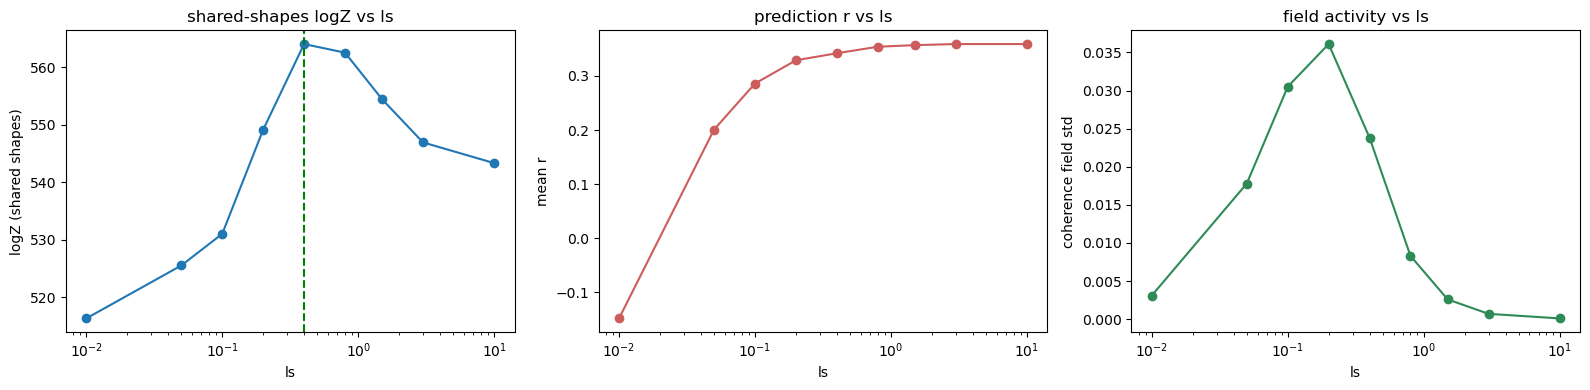

In [5]:
ls_grid = [0.01, 0.05, 0.1, 0.2, 0.4, 0.8, 1.5, 3.0, 10.0]
rows=[]
for lsv in ls_grid:
    lz = inf.total_log_lik_free_shapes(geom, responses_cond, lsv, 0.0, 0.5, beta_speaker=3.0, shared_shapes=True)
    _,sh,_ = inf.total_log_lik_free_shapes(geom, responses_cond, lsv, 0.0, 0.5, beta_speaker=3.0, return_shapes=True, shared_shapes=True)
    mkl=sh[:,0]/(sh[:,0]+sh[:,1]); mnkl=sh[:,2]/(sh[:,2]+sh[:,3])
    pz=inf.prior_pz1_modes(geom,lsv,0.0,0.5,beta_speaker=3.0)
    rs=[np.corrcoef((np.asarray(pz[c])*mkl+(1-np.asarray(pz[c]))*mnkl),emp_cond[c])[0,1] for c in inf.CONDITIONS]
    rows.append({'ls':lsv,'logZ':round(lz,1),'mean_r':round(np.mean(rs),3),
                 'pz1_std':round(np.mean([np.asarray(pz[c]).std() for c in inf.CONDITIONS]),4)})
dfp=pd.DataFrame(rows)
print("SHARED shapes, controlled (mu=0, sigma=0.5, beta=3):")
print(dfp.to_string(index=False))
best=dfp.loc[dfp['logZ'].idxmax()]
print(f"\n--> shared-shapes logZ PEAKS at ls={best['ls']} (local!) with an ACTIVE field (pz1_std>0).")
print(f"    Flat null (ls=10) logZ={dfp[dfp.ls==10.0]['logZ'].values[0]} vs peak {best['logZ']}: "
      f"GP beats flat by +{best['logZ']-dfp[dfp.ls==10.0]['logZ'].values[0]:.1f} logZ.")

fig,axes=plt.subplots(1,3,figsize=(16,4))
axes[0].plot(dfp['ls'],dfp['logZ'],'-o'); axes[0].set_xscale('log'); axes[0].set_xlabel('ls'); axes[0].set_ylabel('logZ (shared shapes)'); axes[0].set_title('shared-shapes logZ vs ls'); axes[0].axvline(best['ls'],color='g',ls='--')
axes[1].plot(dfp['ls'],dfp['mean_r'],'-o',color='indianred'); axes[1].set_xscale('log'); axes[1].set_xlabel('ls'); axes[1].set_ylabel('mean r'); axes[1].set_title('prediction r vs ls')
axes[2].plot(dfp['ls'],dfp['pz1_std'],'-o',color='seagreen'); axes[2].set_xscale('log'); axes[2].set_xlabel('ls'); axes[2].set_ylabel('coherence field std'); axes[2].set_title('field activity vs ls')
plt.tight_layout(); plt.show()


## 5. Side-by-side summary: per-feature vs shared linking

| | per-feature linking | shared linking |
|---|---|---|
| prediction r | ~0.94 | ~0.35 |
| coherence field | nearly flat (inert) | active, prefers ls~0.4 (local) |
| GP vs flat null | ~equal (GP cosmetic) | GP beats null by ~+21 logZ |
| what carries feature variance | the linking function | the coherence field |

**The tension:** per-feature linking predicts far better (r 0.94 vs 0.35) because features genuinely
have idiosyncratic response distributions a single shared Beta-pair can't capture. But that same
flexibility makes the GP/distance story cosmetic. Shared linking forces the GP to work (nuanced
local field, beats null) but throws away real per-feature signal.

**Open modeling decision (for discussion):** which model does the paper want? Or a middle ground
(e.g. shapes shared within trait-category, or a hierarchical/regularized per-feature prior) that
lets the linking function keep SOME per-feature flex without fully masking the GP?


## 6. Coherence field visualization

The GP coherence field P(kind-linked) over the 2d embedding, per condition, for five cases:

1. **per-feature @ fitted** (ls=0.98, beta=0.91) — the honest fit; field is nearly FLAT (inert).
2. **shared-linking @ its preferred ls=0.4** (beta=3) — when forced to work, the field is LOCAL and
   structured (coherence concentrates near each condition's trained features).
3. **old committed** (ls=0.21, beta=16) — the dramatic-LOOKING field (but it barely drove predictions).
4. **per-feature ZOIB linking @ its own VBMC fit** (ls≈0.34, beta≈26; `results/study9-fit-zoib/`) — each
   feature's components are zero/one-inflated, single-peaked Betas (`linking.py`); with that constrained
   linking the fitted field is LOCAL again and beats the flat null, but its swing is small (~0.79–0.85,
   because mu_0≈1.3 sits on the flat part of the sigmoid).
5. **per-feature @ speaker β fixed to study 6's value** (β≈28.9; `results/study9-fit-fixed-beta/`) — the
   original (non-ZOIB) per-feature Beta-mixture linking, with β pinned at the study-6 posterior median and
   ls, μ₀, σ refit to study 9. Asks what the study-9 field looks like when β is as large as study 6 says.

**Stars (★) = trained (kind-linked) features** for that condition; **dots (●) = test features**,
colored by empirical mean rating. Each row shares one color scale so the swing is comparable within
a case; the per-case field range is printed in the row title.

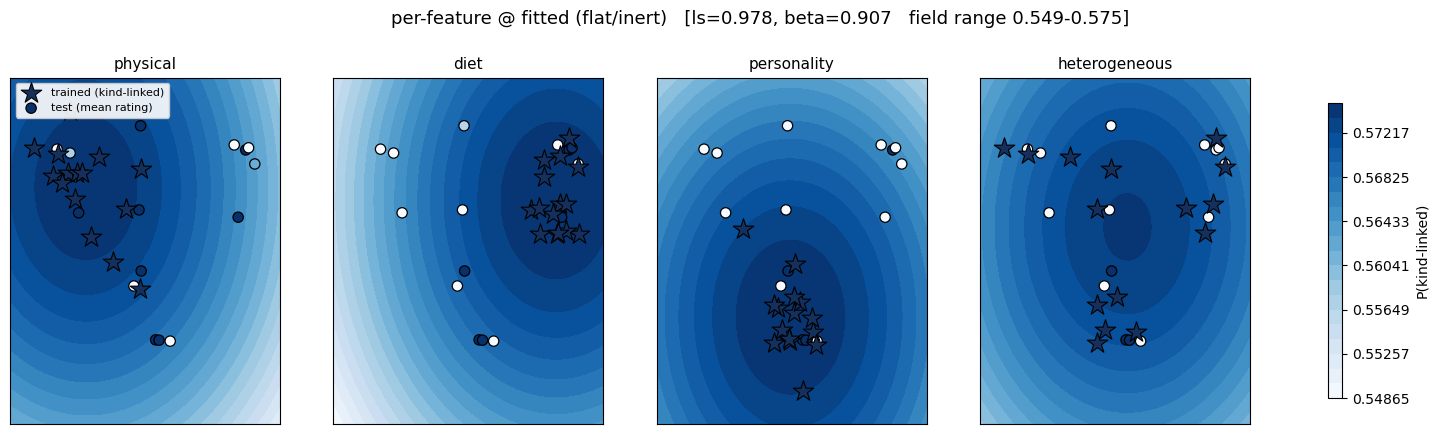

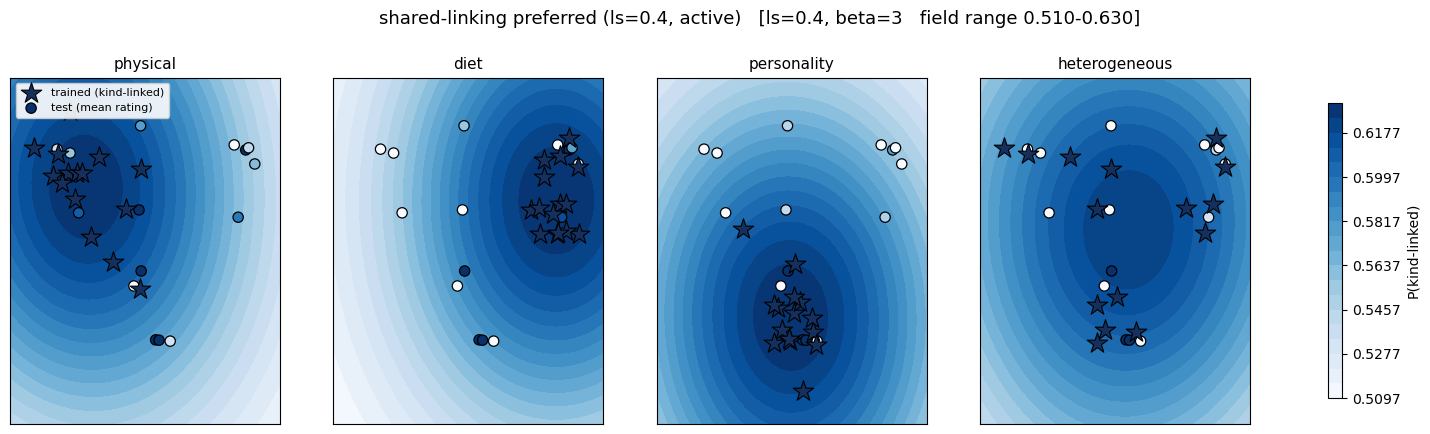

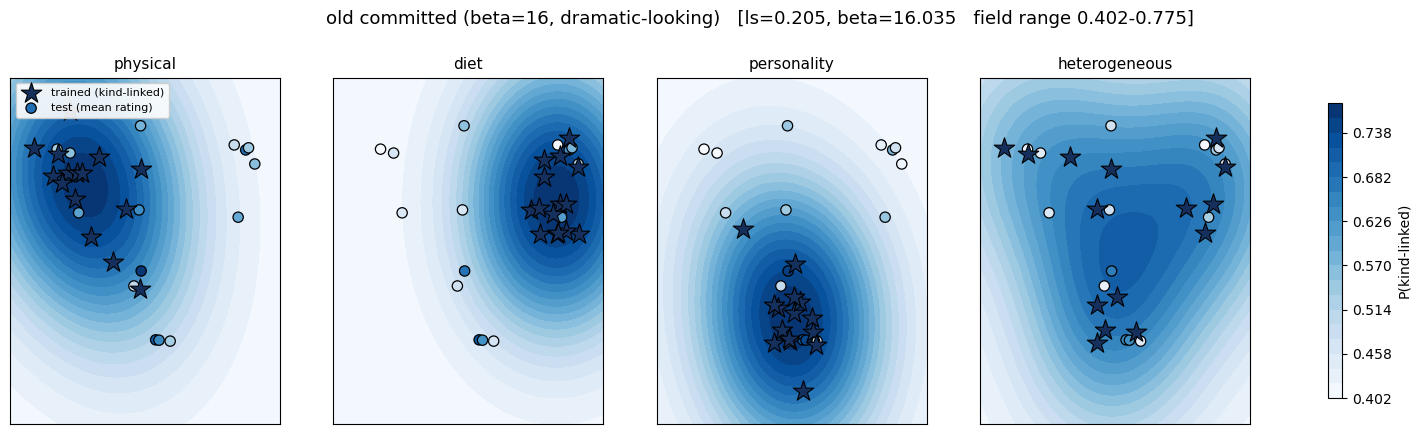

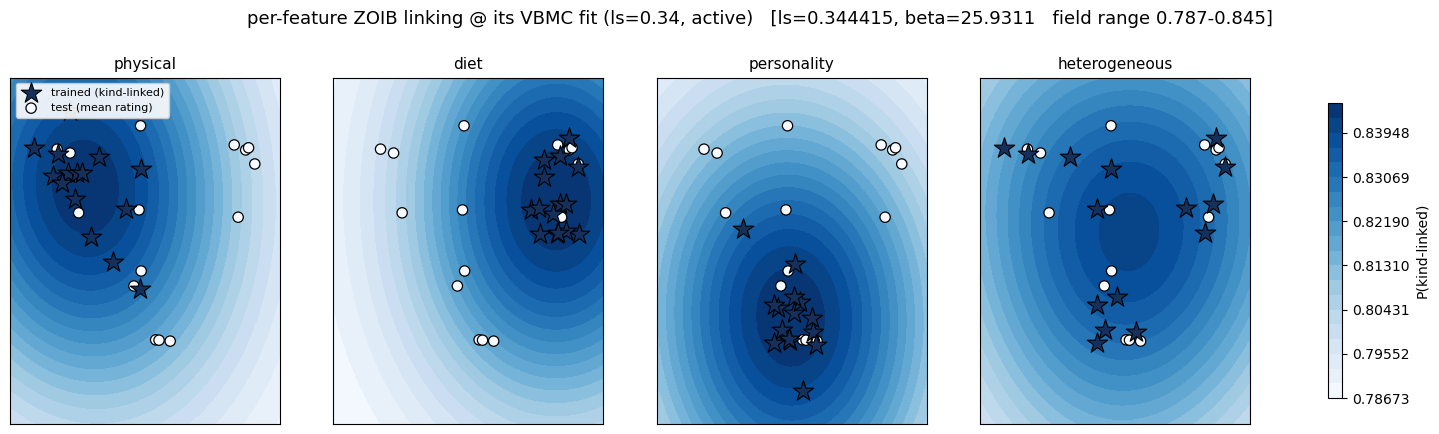

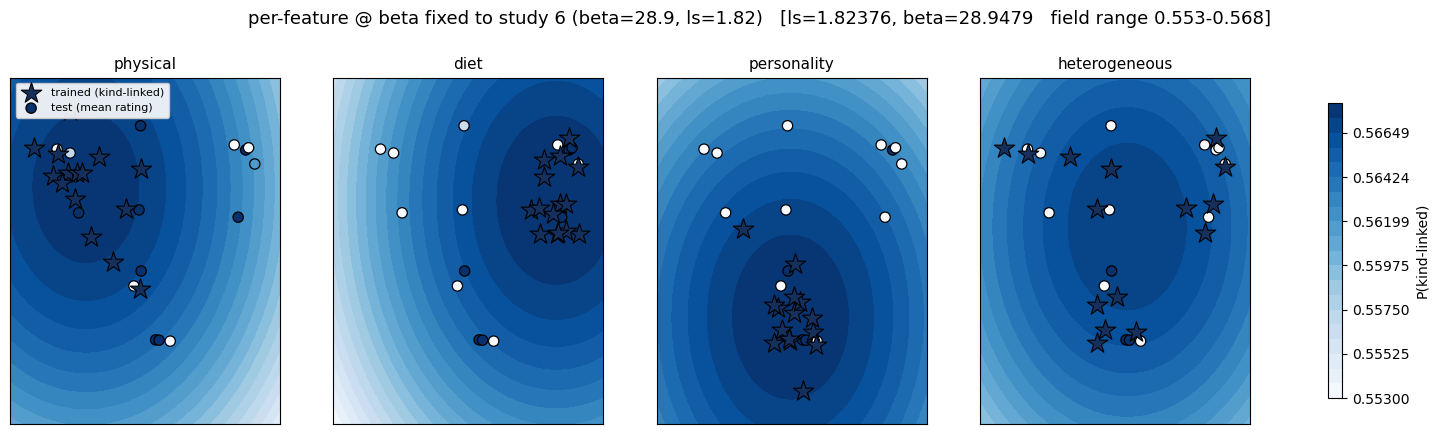

In [6]:
import os
all_x = np.vstack([np.array(geom['x_test'])] + [np.array(geom['x_train_cond'][c]) for c in inf.CONDITIONS])
pad = 0.08
(x_lo, y_lo), (x_hi, y_hi) = all_x.min(0) - pad, all_x.max(0) + pad
gx, gy = np.meshgrid(np.linspace(x_lo, x_hi, 70), np.linspace(y_lo, y_hi, 70))
X_grid = np.column_stack([gx.ravel(), gy.ravel()])
x_test_np = np.array(geom['x_test'])

CASES = [
    ('per-feature @ fitted (flat/inert)', 0.978, 0.006, 0.526, 0.907),
    ('shared-linking preferred (ls=0.4, active)', 0.4, 0.0, 0.5, 3.0),
    ('old committed (beta=16, dramatic-looking)', 0.205, -0.397, 0.782, 16.035),
]

# 4th case: the per-feature ZOIB linking's own VBMC fit (run_parameter_estimation.py study9-zoib),
# posterior median read from its results dir
_zp = np.load(os.path.join('results', 'study9-fit-zoib', 'posterior.npz'), allow_pickle=True)
_zt = [float(np.median(_zp[k])) for k in ('ls_samples', 'mu0_samples', 'sigma_samples', 'beta_samples')]
CASES.append((f'per-feature ZOIB linking @ its VBMC fit (ls={_zt[0]:.2f}, active)', *_zt))

# 5th case: ORIGINAL per-feature Beta-mixture linking, speaker beta pinned at the study-6 posterior
# median (run as results/study9-fit-fixed-beta/; ls, mu_0, sigma refit on study 9), posterior median
_fp = np.load(os.path.join('results', 'study9-fit-fixed-beta', 'fitted-feature-shapes.npz'), allow_pickle=True)
_ft = [float(np.median(_fp[k])) for k in ('ls_samples', 'mu0_samples', 'sigma_samples', 'beta_samples')]
CASES.append((f'per-feature @ beta fixed to study 6 (beta={_ft[3]:.1f}, ls={_ft[0]:.2f})', *_ft))

def plot_field_row(name, ls, mu, sig, beta):
    fields = {c: inf.gp_coherence_field(geom, c, ls, mu, sig, X_grid, beta_speaker=beta).reshape(gx.shape)
              for c in inf.CONDITIONS}
    vmin = min(f.min() for f in fields.values()); vmax = max(f.max() for f in fields.values())
    lv = np.linspace(vmin, vmax, 21) if vmax - vmin > 1e-6 else np.linspace(vmin-1e-3, vmax+1e-3, 21)
    fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
    for ax, c in zip(axes, inf.CONDITIONS):
        cs = ax.contourf(gx, gy, fields[c], levels=lv, cmap='Blues')
        x_tr = np.array(geom['x_train_cond'][c])
        # trained points = STARS; test points = DOTS (colored by empirical mean rating)
        ax.scatter(x_tr[:,0], x_tr[:,1], marker='*', s=240, color='#16305e', edgecolor='k',
                   linewidth=0.8, zorder=4, label='trained (kind-linked)')
        ax.scatter(x_test_np[:,0], x_test_np[:,1], marker='o', s=55, c=emp_cond[c], cmap='Blues',
                   norm=cs.norm, edgecolor='k', linewidth=0.9, zorder=3, label='test (mean rating)')
        ax.set_title(c, fontsize=11); ax.set_xticks([]); ax.set_yticks([])
    axes[0].legend(fontsize=8, loc='upper left', framealpha=0.9)
    fig.colorbar(cs, ax=axes.ravel().tolist(), shrink=0.85, label='P(kind-linked)')
    fig.suptitle(f"{name}   [ls={ls:g}, beta={beta:g}   field range {vmin:.3f}-{vmax:.3f}]",
                 fontsize=13, y=1.03)
    plt.show()

for name, ls, mu, sig, beta in CASES:
    plot_field_row(name, ls, mu, sig, beta)


### Reading the fields

- **per-feature @ fitted**: the field is a smooth, near-uniform wash (tiny range) — visibly inert.
  Yet this model predicts best (r=0.94), because the per-feature linking function (not shown) carries
  the feature variance.
- **shared-linking @ ls=0.4**: coherence concentrates in tight blobs around each condition's trained
  features — the localized, "nuanced" field. This is what the GP does when it HAS to explain features.
- **old committed (beta=16)**: dramatic-looking (wide range), but this drama came from high beta, and
  the field still contributed only ~+0.01 to prediction r.
- **per-feature ZOIB @ its fit**: local blobs around each condition's trained features, like the shared-linking
  case, but with per-feature linking kept, and on the preregistered data the fitted field beats the flat null
  (+6.9 ELBO, +10.8 held-out log-lik; see `study9-gp-vs-flat-zoib.ipynb`). The range is narrow, so the row's
  color scale is stretched over ~0.05. Note the test dots are colored on the field's scale, so ratings below
  its range all show as the lightest shade.

- **per-feature @ β fixed to study 6 (β≈28.9)**: just as flat as the free-β fit (range 0.553–0.568). Pinning β high
  doesn't bring back the dramatic field. The fit compensates: σ drops to 0.29 (vs 0.53 free) and ls grows to 1.8
  (vs 0.98), which cancels the stronger speaker evidence. The data prefer a weak field under per-feature
  linking whatever β is. Pinning costs about 9 ELBO against the free-β fit (974.5 vs 983.3; that fit's VBMC
  status is "no", so read the gap loosely), and the fixed-β full model still beats its own flat null by
  about 11 ELBO (974.5 vs 963.3).

The visual you remember (dramatic/localized) corresponds to either high beta (cosmetic) or the
shared-linking regime (where the GP genuinely works but overall prediction is worse). The honest
per-feature fit looks flat because the linking function is doing the work.